# Credit Scoring — Scorecard Analysis

Reads the saved validation-set predictions produced by Notebook 3 (Training &
Analysis), converts predicted default probabilities (PDs) to credit scores using
the industry-standard PDO (Points to Double the Odds) formula, and produces a
full scorecard analysis.

**Pipeline overview**
1. Configuration — PDO parameters, paths, score range
2. Load saved predictions from Notebook 3
3. Convert PDs → credit scores (PDO formula)
4. Assign risk bands (A–E)
5. Score band analysis — volume & bad rate chart
6. Score distribution histogram
7. KS statistic
8. Save all outputs

**Prerequisite:** Model training must have been run first —
it saves `test_predictions.parquet` which this notebook reads.

**Outputs**
- `data/ScoreOutput/scored_predictions.parquet`
- `data/ScoreOutput/scoreband_summary.csv`
- `data/ScoreOutput/score_band_chart.png`
- `data/ScoreOutput/score_distribution.png`

## 1. Imports & Configuration

All PDO parameters and score-range bounds are defined here as named constants
so they are easy to find and change in one place.

**PDO parameters**
- `PDO = 20` — every 20 score points, the odds of default double
- `BASE_SCORE = 600` — the score assigned to a borrower at the base odds
- `BASE_ODDS = 50` — at `BASE_SCORE`, for every 1 default there are 50 non-defaults
- `MIN_SCORE / MAX_SCORE` — clip extremes to a recognisable scale

In [19]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

# ── Paths ──────────────────────────────────────────────────────────────────
PROJECT_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"a:\Dominic\My Projects\Home Credit")

DATA_ROOT = os.environ.get("HOMECREDIT_DATA_ROOT", r"a:\Dominic\My Projects\Home Credit\data")
SRC_ROOT  = os.environ.get("HOMECREDIT_SRC_DIR", r"a:\Dominic\My Projects\Home Credit\src")

PATH_TEST_PREDICTIONS = os.path.join(DATA_ROOT, "ModelOutput", "LightGBM_v1")
PATH_TEST_DATASET = os.path.join(PATH_TEST_PREDICTIONS, "test_predictions.parquet")

# Outputs
MODELS_DIR         = os.path.join(DATA_ROOT, "ScoreOutput")
PATH_SCORED_OUTPUT = os.path.join(MODELS_DIR, "scored_predictions.parquet")
PATH_SUMMARY_CSV   = os.path.join(MODELS_DIR, "scoreband_summary.csv")
PATH_BAND_CHART    = os.path.join(MODELS_DIR, "score_band_chart.png")
PATH_DIST_CHART    = os.path.join(MODELS_DIR, "score_distribution.png")

# ── PDO scoring parameters ─────────────────────────────────────────────────
PDO        = 20      # points to double the odds
BASE_SCORE = 600     # score at BASE_ODDS
BASE_ODDS  = 50      # good:bad odds at BASE_SCORE
MIN_SCORE  = 300     # floor
MAX_SCORE  = 850     # ceiling

print(f"Reading predictions from : {PATH_TEST_PREDICTIONS}")
print(f"Outputs to               : {MODELS_DIR}")

Reading predictions from : a:\Dominic\My Projects\Home Credit\data\ModelOutput\LightGBM_v1
Outputs to               : a:\Dominic\My Projects\Home Credit\data\ScoreOutput


## 2. Load Saved Predictions

`test_predictions.parquet` is saved by training notebook right after training. It contains one row per validation-set applicant with:
- `SK_ID_CURR` — applicant identifier
- `TARGET` — true label (1 = default, 0 = non-default)
- `predicted_proba` — model's predicted probability of default
- `predicted_label` — binary prediction at the optimal threshold

No model loading, no re-splitting, no sync of `RANDOM_STATE`/`TEST_SIZE` needed.

In [7]:
predictions_df = pd.read_parquet(PATH_TEST_DATASET)

print(f"Loaded {len(predictions_df):,} validation predictions")
print(f"Default rate : {predictions_df['TARGET'].mean():.2%}")
print(f"PD range     : [{predictions_df['predicted_proba'].min():.4f}, "
      f"{predictions_df['predicted_proba'].max():.4f}]")
predictions_df.head(3)

Loaded 61,503 validation predictions
Default rate : 8.07%
PD range     : [0.0015, 0.7935]


,SK_ID_CURR,TARGET,predicted_proba
295854,442770,0,0.012406
60948,170683,0,0.370436
217030,351470,0,0.109818


## 3. Convert PDs to Credit Scores (PDO Formula)

The industry-standard PDO (Points to Double the Odds) transformation converts a
continuous probability of default into an integer score where:
- **Higher score = lower risk** (inverse of PD)
- Every `PDO` points on the scale represents a doubling of the good:bad odds

$$\text{score} = \text{offset} + \text{factor} \times \ln\left(\frac{1 - PD}{PD}\right)$$

where $\text{factor} = PDO / \ln(2)$ and
$\text{offset} = \text{BASE\_SCORE} - \text{factor} \times \ln(\text{BASE\_ODDS})$

In [ ]:
def pd_to_score(
    prob_default,
    pdo=PDO, base_score=BASE_SCORE, base_odds=BASE_ODDS,
    min_score=MIN_SCORE, max_score=MAX_SCORE,
):
    """
    Convert predicted probability of default to a credit score.

    All PDO parameters are explicit arguments — function never reads module-level
    globals so it is safe to rerun in any cell order.
    
    Parameters
    ----------
    prob_default : float or array — predicted P(default) from the model, in [0, 1]
    pdo          : points to double the odds (industry standard: 20)
    base_score   : score assigned at base_odds (e.g. 600)
    base_odds    : good:bad odds ratio at base_score (e.g. 50 means 50:1)
    min_score    : floor — extreme values clipped here
    max_score    : ceiling — extreme values clipped here

    Returns
    -------
    np.ndarray of int — credit scores clipped to [min_score, max_score]
    """
    factor = pdo / np.log(2)
    offset = base_score - factor * np.log(base_odds)
    prob_default = np.asarray(prob_default, dtype=float)
    odds  = (1 - prob_default) / (prob_default + 1e-10)
    score = offset + factor * np.log(odds)
    return np.clip(np.round(score).astype(int), min_score, max_score)


# Sanity check — higher PD must always map to lower score
test_pds = np.array([0.0001, 0.001, 0.01, 0.05, 0.10, 0.20, 0.40, 0.60, 0.80])
print(pd.DataFrame({'PD': test_pds, 'Score': pd_to_score(test_pds)}).to_string(index=False))

    PD  Score
0.0001    753
0.0010    686
0.0100    620
0.0500    572
0.1000    551
0.2000    527
0.4000    499
0.6000    475
0.8000    447


In [13]:
predictions_df['score'] = pd_to_score(predictions_df['predicted_proba'])

print(f"Score range : [{predictions_df['score'].min()}, {predictions_df['score'].max()}]")
print(f"Mean score  : {predictions_df['score'].mean():.1f}")
print(f"Median score: {predictions_df['score'].median():.1f}")

Score range : [448, 675]
Mean score  : 572.2
Median score: 574.0


## 5. Assign Risk Bands

Assigns each applicant to a named risk band based on fixed score thresholds.
Fixed thresholds (rather than equal-volume deciles) are preferable for business
use because the band label for a given score stays consistent as the portfolio
mix changes over time — decile boundaries would shift with the population.

| Band | Score Range | Interpretation |
|---|---|---|
| A | ≥ 650 | Very low risk — automatic approve candidate |
| B | 620 – 649 | Low risk — standard terms |
| C | 590 – 619 | Medium risk — review or enhanced terms |
| D | 560 – 589 | High risk — manual underwriting |
| E | < 560 | Very high risk — decline candidate |

In [17]:
BAND_BINS   = [MIN_SCORE, 560, 590, 620, 650, MAX_SCORE + 1]
BAND_LABELS = ['E — Very High Risk', 'D — High Risk', 'C — Medium Risk',
               'B — Low Risk', 'A — Very Low Risk']

predictions_df['Risk_Band'] = pd.cut(
    predictions_df['score'],
    bins=BAND_BINS,
    labels=BAND_LABELS,
    right=False,
)

band_summary = predictions_df.groupby('Risk_Band', observed=True).agg(
    Applicant_Count=('TARGET', 'count'),
    Bad_Count=('TARGET', 'sum'),
    Mean_Score=('score', 'mean'),
    Mean_PD=('predicted_proba', 'mean'),
).reset_index()
band_summary['Bad_Rate'] = band_summary['Bad_Count'] / band_summary['Applicant_Count']
band_summary['Volume_Pct'] = band_summary['Applicant_Count'] / band_summary['Applicant_Count'].sum()

print(band_summary[['Risk_Band', 'Applicant_Count', 'Volume_Pct', 'Bad_Rate', 'Mean_Score', 'Mean_PD']]
      .to_string(index=False, float_format='{:.4f}'.format))

         Risk_Band  Applicant_Count  Volume_Pct  Bad_Rate  Mean_Score  Mean_PD
E — Very High Risk            20501      0.3333    0.1766    535.5152   0.1758
     D — High Risk            21346      0.3471    0.0480    574.9283   0.0473
   C — Medium Risk            15971      0.2597    0.0183    602.2792   0.0188
      B — Low Risk             3551      0.0577    0.0079    628.6483   0.0076
 A — Very Low Risk              134      0.0022    0.0000    655.0821   0.0030


## 6. Score Band Analysis — Volume & Bad Rate Chart

Splits the population into 10 equal-volume deciles (score bands) and plots
applicant count on the left axis against the default rate on the right axis.
A well-discriminating model should show a monotonically decreasing bad rate
from the lowest score band (highest risk) to the highest score band (lowest risk).

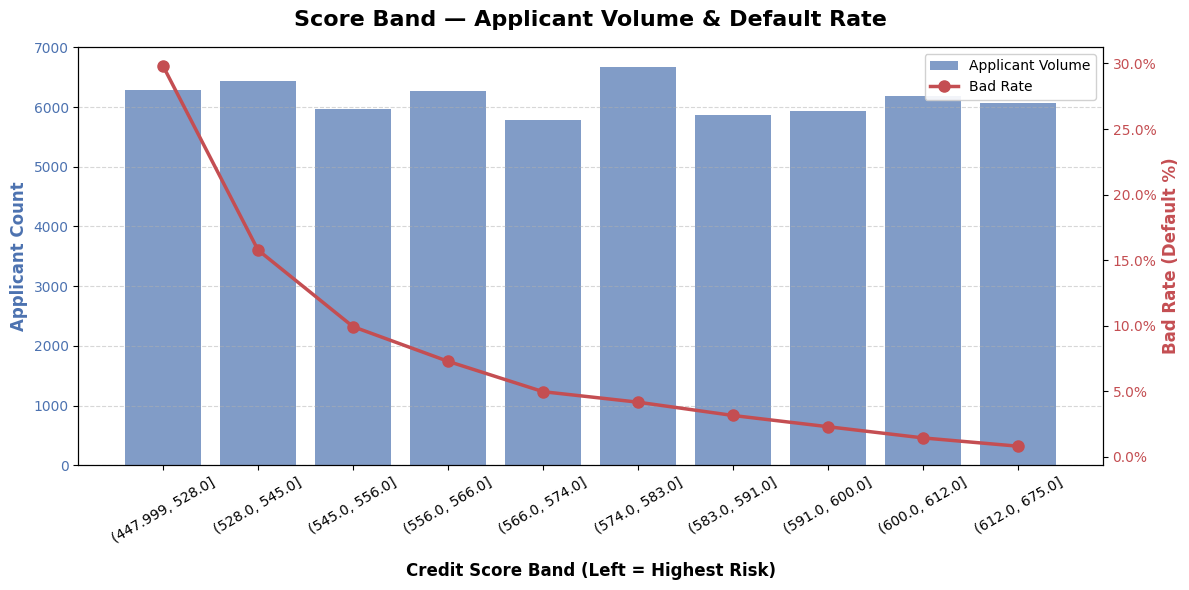

Saved → a:\Dominic\My Projects\Home Credit\data\ScoreOutput\score_band_chart.png
  Score_Band_Str  Applicant_Count  Bad_Count  Bad_Rate
(447.999, 528.0]             6291       1876  0.298204
  (528.0, 545.0]             6436       1015  0.157707
  (545.0, 556.0]             5974        593  0.099263
  (556.0, 566.0]             6277        457  0.072805
  (566.0, 574.0]             5779        287  0.049663
  (574.0, 583.0]             6676        278  0.041642
  (583.0, 591.0]             5873        185  0.031500
  (591.0, 600.0]             5935        136  0.022915
  (600.0, 612.0]             6186         89  0.014387
  (612.0, 675.0]             6076         49  0.008065


In [21]:
predictions_df['Score_Band'] = pd.qcut(
    predictions_df['score'], q=10, duplicates='drop'
)

summary = predictions_df.groupby('Score_Band', observed=True).agg(
    Applicant_Count=('TARGET', 'count'),
    Bad_Count=('TARGET', 'sum'),
).reset_index()
summary['Bad_Rate']      = summary['Bad_Count'] / summary['Applicant_Count']
summary['Score_Band_Str'] = summary['Score_Band'].astype(str)

fig, ax1 = plt.subplots(figsize=(12, 6))

COLOR_BAR  = '#4C72B0'
COLOR_LINE = '#C44E52'

ax1.bar(summary['Score_Band_Str'], summary['Applicant_Count'],
        color=COLOR_BAR, alpha=0.7, label='Applicant Volume')
ax1.set_xlabel('Credit Score Band (Left = Highest Risk)', fontsize=12,
               fontweight='bold', labelpad=12)
ax1.set_ylabel('Applicant Count', color=COLOR_BAR, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=COLOR_BAR)
ax1.tick_params(axis='x', rotation=30)

ax2 = ax1.twinx()
ax2.plot(summary['Score_Band_Str'], summary['Bad_Rate'],
         color=COLOR_LINE, marker='o', markersize=8, linewidth=2.5, label='Bad Rate')
ax2.set_ylabel('Bad Rate (Default %)', color=COLOR_LINE, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=COLOR_LINE)
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.title('Score Band — Applicant Volume & Default Rate', fontsize=16,
          fontweight='bold', pad=15)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', framealpha=0.9)

plt.tight_layout()
fig.savefig(PATH_BAND_CHART, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {PATH_BAND_CHART}")

print(summary[['Score_Band_Str', 'Applicant_Count', 'Bad_Count', 'Bad_Rate']].to_string(index=False))

## 7. Score Distribution Histogram

> **Note:** The x-axis limits
> are now set from `MIN_SCORE` / `MAX_SCORE` so the full configured range is always shown.

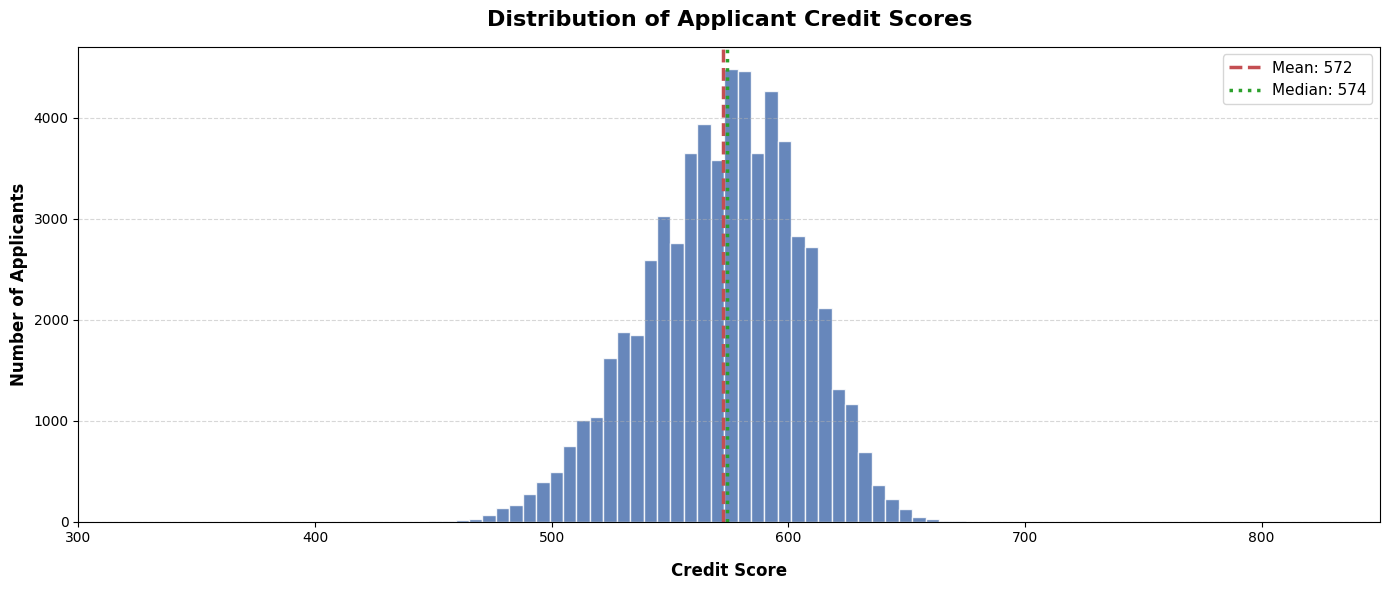

Saved → a:\Dominic\My Projects\Home Credit\data\ScoreOutput\score_distribution.png


In [22]:
fig2, ax = plt.subplots(figsize=(14, 6))

ax.hist(predictions_df['score'], bins=40, color='#4C72B0', edgecolor='white', alpha=0.85)

mean_score   = predictions_df['score'].mean()
median_score = predictions_df['score'].median()
ax.axvline(mean_score,   color='#C44E52', linestyle='dashed', linewidth=2.5,
           label=f'Mean: {mean_score:.0f}')
ax.axvline(median_score, color='#2CA02C', linestyle='dotted', linewidth=2.5,
           label=f'Median: {median_score:.0f}')

# FIX: xlim from config constants, not hardcoded 400-700
ax.set_xlim(MIN_SCORE, MAX_SCORE)
ax.set_title('Distribution of Applicant Credit Scores', fontsize=16,
             fontweight='bold', pad=15)
ax.set_xlabel('Credit Score', fontsize=12, fontweight='bold', labelpad=12)
ax.set_ylabel('Number of Applicants', fontsize=12, fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(fontsize=11)

plt.tight_layout()
fig2.savefig(PATH_DIST_CHART, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {PATH_DIST_CHART}")

## 8. KS Statistic

The Kolmogorov-Smirnov (KS) statistic measures the maximum separation between the
cumulative distribution of scores for defaulters vs. non-defaulters. A higher KS
means the model better separates the two groups.

General benchmarks (credit risk context):
- KS < 20: poor discrimination
- KS 20–40: acceptable
- KS 40–60: good
- KS > 60: excellent (verify for overfitting)

> **Note:** KS is computedon every individual record using `scipy.stats.ks_2samp` — the mathematically
> correct approach — followed by the traditional KS table on the decile bands
> for business reporting.

In [23]:
# FIX: compute KS on all individual records, not aggregated buckets
scores_good = predictions_df.loc[predictions_df['TARGET'] == 0, 'score']
scores_bad  = predictions_df.loc[predictions_df['TARGET'] == 1, 'score']

ks_result = stats.ks_2samp(scores_good, scores_bad)
print(f"KS Statistic (scipy, record-level) : {ks_result.statistic * 100:.2f}")
print(f"p-value                             : {ks_result.pvalue:.2e}")
print()

KS Statistic (scipy, record-level) : 43.26
p-value                             : 0.00e+00



In [24]:
# KS table on decile bands — useful for business reporting and scorecard documentation
summary['Good_Count']  = summary['Applicant_Count'] - summary['Bad_Count']
summary['Bad_Pct']     = summary['Bad_Count']  / summary['Bad_Count'].sum()
summary['Good_Pct']    = summary['Good_Count'] / summary['Good_Count'].sum()
summary['Cum_Bad_Pct'] = summary['Bad_Pct'].cumsum()
summary['Cum_Good_Pct']= summary['Good_Pct'].cumsum()
summary['KS_Spread']   = (summary['Cum_Bad_Pct'] - summary['Cum_Good_Pct']).abs() * 100

ks_band = summary.loc[summary['KS_Spread'].idxmax(), 'Score_Band_Str']
print(f"KS Statistic (decile table)         : {summary['KS_Spread'].max():.2f}")
print(f"Maximum separation at score band    : {ks_band}")
print()
print('--- Decile KS Table ---')
ks_cols = ['Score_Band_Str', 'Applicant_Count', 'Bad_Rate',
           'Cum_Bad_Pct', 'Cum_Good_Pct', 'KS_Spread']
print(summary[ks_cols].to_string(index=False, float_format='{:.4f}'.format))

KS Statistic (decile table)         : 43.26
Maximum separation at score band    : (545.0, 556.0]

--- Decile KS Table ---
  Score_Band_Str  Applicant_Count  Bad_Rate  Cum_Bad_Pct  Cum_Good_Pct  KS_Spread
(447.999, 528.0]             6291    0.2982       0.3778        0.0781    29.9756
  (528.0, 545.0]             6436    0.1577       0.5823        0.1740    40.8304
  (545.0, 556.0]             5974    0.0993       0.7017        0.2691    43.2566
  (556.0, 566.0]             6277    0.0728       0.7938        0.3721    42.1670
  (566.0, 574.0]             5779    0.0497       0.8516        0.4692    38.2337
  (574.0, 583.0]             6676    0.0416       0.9076        0.5824    32.5166
  (583.0, 591.0]             5873    0.0315       0.9448        0.6830    26.1822
  (591.0, 600.0]             5935    0.0229       0.9722        0.7856    18.6645
  (600.0, 612.0]             6186    0.0144       0.9901        0.8934     9.6732
  (612.0, 675.0]             6076    0.0081       1.0000  

## 9. Save Outputs

In [35]:
cols_to_convert = ['Risk_Band', 'Score_Band']
predictions_df[cols_to_convert] = predictions_df[cols_to_convert].astype(str)

In [36]:
# Full scored predictions — one row per applicant
predictions_df.to_parquet(PATH_SCORED_OUTPUT, index=False)
print(f"Saved scored predictions → {PATH_SCORED_OUTPUT}")

# Scoreband summary table (decile + risk band)
summary.to_csv(PATH_SUMMARY_CSV, index=False)
print(f"Saved scoreband summary  → {PATH_SUMMARY_CSV}")

print(f"\nFinal scored dataset shape: {predictions_df.shape}")
print(f"Columns: {predictions_df.columns.tolist()}")

Saved scored predictions → a:\Dominic\My Projects\Home Credit\data\ScoreOutput\scored_predictions.parquet
Saved scoreband summary  → a:\Dominic\My Projects\Home Credit\data\ScoreOutput\scoreband_summary.csv

Final scored dataset shape: (61503, 6)
Columns: ['SK_ID_CURR', 'TARGET', 'predicted_proba', 'score', 'Risk_Band', 'Score_Band']


## 10. Cleanup

In [ ]:
del predictions_df, summary
import gc; gc.collect()
print("All DataFrames released.")